# ML Mini Project — Phase 1
## Predicting and Classifying Air Quality Index (AQI)

**Dataset:** `air_quality_dataset.csv` — daily air quality readings across 15 major US cities (2023–2024)

## 1. Dataset Identification

We chose the **Air Quality Dataset** — a collection of daily air-quality and weather
observations for 15 major US cities, spanning January 2023 to December 2024. Each row
represents one city on one day, recording the AQI reading alongside the concentrations
of the six pollutants that feed into it, plus temperature and humidity for that day.

We picked this dataset over two other candidates we considered (an India-wide CPCB AQI
feed, and the UCI Air Quality gas-sensor dataset) because it is the only one of the three
that gives us a genuine, non-circular AQI target paired with real numeric predictors
(pollutant concentrations + weather) — which is exactly what both a regression task
(predicting the AQI value) and a classification task (predicting the AQI category) need.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 110

df = pd.read_csv("air_quality_dataset.csv", parse_dates=["Date"])
print(f"Rows x Columns: {df.shape[0]} x {df.shape[1]}")
df.head()

Rows x Columns: 5583 x 11


,Date,City,AQI,PM2.5,PM10,Ozone,NO2,CO,SO2,Temperature,Humidity
0,2024-10-16,Los Angeles,128.0,28.78,68.84,58.29,57.56,2.781,17.10,3.4,82.2
1,2023-01-26,Jacksonville,111.0,28.73,61.93,59.00,35.73,1.810,16.33,17.0,36.0
2,2023-10-09,Houston,91.0,20.04,47.10,66.20,43.91,2.566,15.27,1.0,68.6
3,2023-08-17,Chicago,108.0,23.39,47.90,62.85,48.89,2.332,18.49,9.4,85.7
4,2023-04-15,Austin,106.0,26.51,56.08,62.38,NaN,1.867,15.93,17.3,48.7


## 2. Dataset Metadata

In [2]:
meta = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isnull().sum(),
    "missing_%": (df.isnull().mean() * 100).round(2),
    "unique_values": df.nunique()
})
meta

,dtype,missing_values,missing_%,unique_values
Date,datetime64[us],0,0.00,730
City,str,0,0.00,15
AQI,float64,111,1.99,141
PM2.5,float64,97,1.74,1874
PM10,float64,60,1.07,3168
Ozone,float64,75,1.34,3478
NO2,float64,93,1.67,2287
CO,float64,162,2.90,1723
SO2,float64,129,2.31,1595
Temperature,float64,148,2.65,520


| Field | Detail |
|---|---|
| **Records** | 5,583 daily observations |
| **Features** | 11 columns (1 date, 1 categorical, 9 numeric) |
| **Time span** | 2023-01-01 to 2024-12-30 (2 years) |
| **Geographic coverage** | 15 US cities (Los Angeles, New York, Chicago, Houston, Phoenix, Philadelphia, San Antonio, San Diego, Dallas, San Jose, Austin, Jacksonville, Fort Worth, Columbus, Charlotte) |
| **Target variable (regression)** | `AQI` — continuous, 46 to 497 |
| **Target variable (classification)** | `AQI_Category` — engineered from `AQI` using standard EPA breakpoints (built in Section 5) |
| **Predictor features** | `PM2.5`, `PM10`, `Ozone`, `NO2`, `CO`, `SO2` (pollutant concentrations), `Temperature`, `Humidity` (weather), `City` (categorical location) |
| **Missing data** | Present in every numeric column, roughly 1–3% per column (97–162 rows) |
| **Duplicate rows** | 86 exact duplicate records |
| **Format** | Single CSV, comma-separated, UTF-8 |

## 3. Problem Statement

Air quality directly affects public health, and timely, accurate AQI information lets
individuals and authorities take preventive action (e.g. issuing advisories, restricting
outdoor activity). However, AQI readings are not always available in real time everywhere
pollutant sensors and weather stations report data. This project asks:

> **Given a city's daily pollutant concentrations (PM2.5, PM10, Ozone, NO2, CO, SO2) and
> weather conditions (temperature, humidity), can we (a) predict the numeric AQI value,
> and (b) classify the day into an AQI health-advisory category?**

## 4. Objectives

1. Perform exploratory data analysis to understand pollutant distributions, missing-data
   patterns, inter-pollutant correlations, and how AQI varies across cities and time.
2. Build a reproducible preprocessing pipeline that handles missing values, engineers
   useful features from the date field, and encodes the categorical `City` feature.
3. Frame two complementary supervised-learning problems from the same data:
   - **Regression:** predict the continuous `AQI` value.
   - **Classification:** predict the categorical AQI health-advisory band.
4. Shortlist at least six candidate models — spanning linear, instance-based,
   probabilistic/tree-based, and ensemble approaches — for implementation and comparison
   in Phase 2.

## 5. Exploratory Data Analysis

### 5.1 Missing data

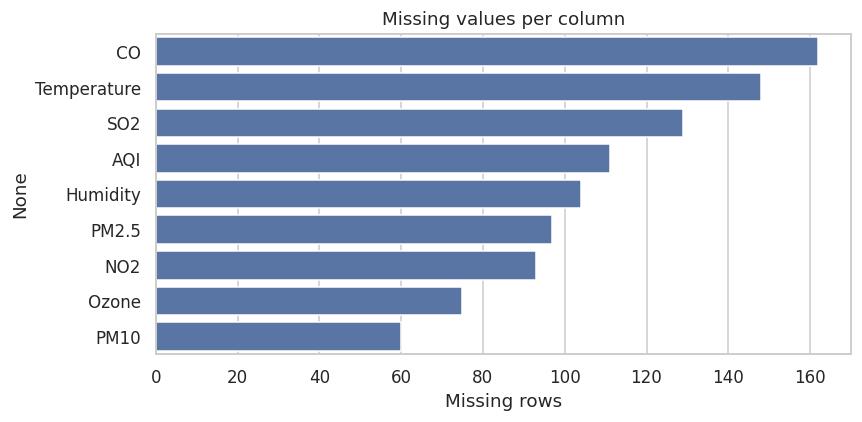

Total duplicate rows: 86


In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
sns.barplot(x=missing.values, y=missing.index, ax=ax, color="#4C72B0")
ax.set_xlabel("Missing rows")
ax.set_title("Missing values per column")
plt.tight_layout()
plt.show()

print(f"Total duplicate rows: {df.duplicated().sum()}")

Every numeric column has a small amount (1–3%) of missing data, scattered fairly evenly
rather than concentrated in a few rows — this rules out simply dropping rows and points
to per-column imputation instead. There are also 86 exact duplicate rows to remove.

### 5.2 Target variable — AQI distribution

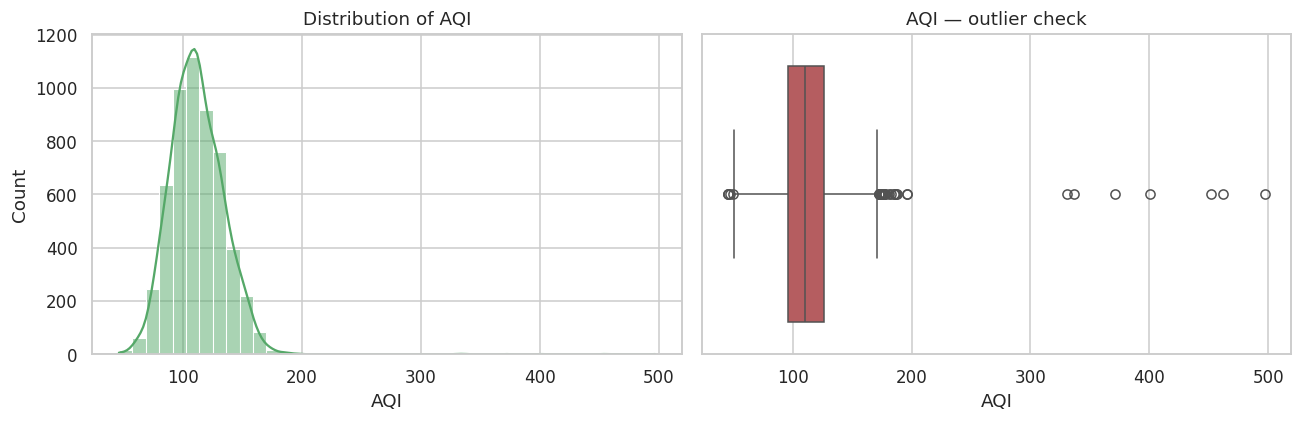

count    5472.000000
mean      111.969664
std        24.152583
min        46.000000
25%        96.000000
50%       110.000000
75%       126.000000
max       497.000000
Name: AQI, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["AQI"].dropna(), bins=40, kde=True, ax=axes[0], color="#55A868")
axes[0].set_title("Distribution of AQI")
sns.boxplot(x=df["AQI"].dropna(), ax=axes[1], color="#C44E52")
axes[1].set_title("AQI — outlier check")
plt.tight_layout()
plt.show()

print(df["AQI"].describe())

AQI is right-skewed: most days sit between 90 and 130, but a long tail of high-pollution
days stretches out to nearly 500. Those high values are genuine hazardous-air-quality
events, not data errors, so we keep them rather than treating them as outliers to remove —
but we will need models that can handle a skewed, long-tailed target.

### 5.3 AQI health-advisory categories (preview of classification target)

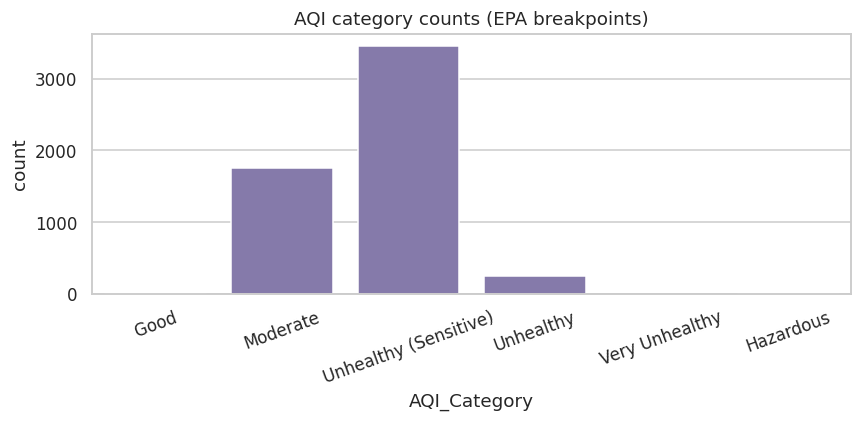

AQI_Category
Unhealthy (Sensitive)    3456
Moderate                 1756
Unhealthy                 248
NaN                       111
Hazardous                   7
Good                        5
Very Unhealthy              0
Name: count, dtype: int64

In [5]:
def categorize_aqi(aqi):
    if pd.isna(aqi):
        return np.nan
    if aqi <= 50:
        return "Good"
    elif aqi <= 100:
        return "Moderate"
    elif aqi <= 150:
        return "Unhealthy (Sensitive)"
    elif aqi <= 200:
        return "Unhealthy"
    elif aqi <= 300:
        return "Very Unhealthy"
    else:
        return "Hazardous"

cat_order = ["Good", "Moderate", "Unhealthy (Sensitive)", "Unhealthy", "Very Unhealthy", "Hazardous"]
df["AQI_Category"] = pd.Categorical(df["AQI"].apply(categorize_aqi), categories=cat_order, ordered=True)

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(x=df["AQI_Category"], order=cat_order, ax=ax, color="#8172B2")
ax.set_title("AQI category counts (EPA breakpoints)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

df["AQI_Category"].value_counts(dropna=False)

The classes are heavily imbalanced: roughly 62% of days fall in "Unhealthy (Sensitive)"
alone, while "Good" and "Hazardous" each account for well under 1% of days. This is an
important flag for Phase 2 — classification models will need `class_weight='balanced'`,
stratified train/test splitting, and evaluation metrics beyond raw accuracy (e.g.
macro-F1) rather than naive resampling at this stage.

### 5.4 Correlations between pollutants, weather, and AQI

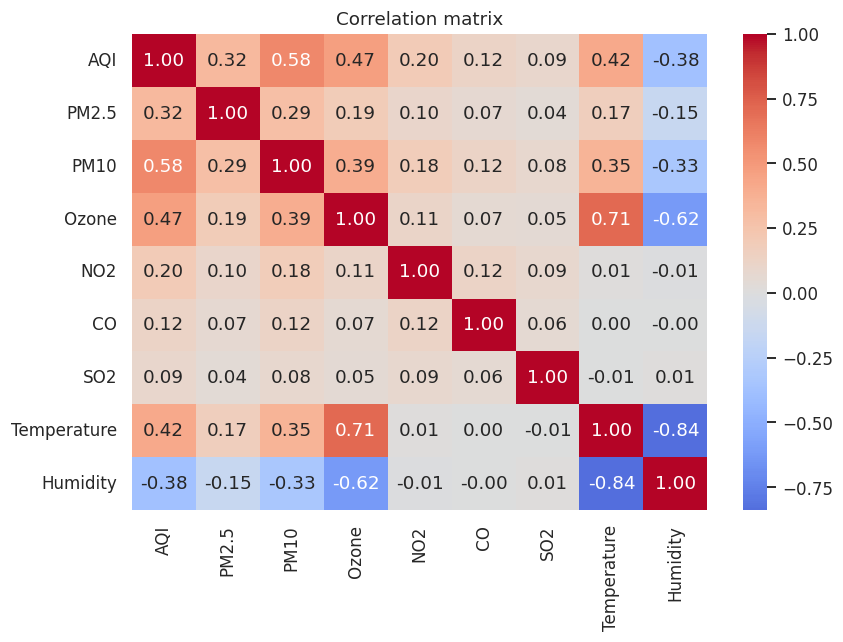

AQI            1.000000
PM10           0.581504
Ozone          0.473272
Temperature    0.416951
PM2.5          0.321194
NO2            0.201573
CO             0.116200
SO2            0.091323
Humidity      -0.375323
Name: AQI, dtype: float64

In [6]:
num_cols = ["AQI", "PM2.5", "PM10", "Ozone", "NO2", "CO", "SO2", "Temperature", "Humidity"]
corr = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

corr["AQI"].sort_values(ascending=False)

`PM10` (r ≈ 0.58) and `Ozone` (r ≈ 0.47) are the strongest positive drivers of AQI,
followed by `Temperature` (r ≈ 0.42) — consistent with real-world atmospheric chemistry,
where heat accelerates ozone formation. `Humidity` is moderately negative (r ≈ -0.38),
while `CO` and `SO2` contribute comparatively little in this dataset. No pair of
predictors is severely collinear (all |r| < 0.6 among predictors), so multicollinearity
is unlikely to be a serious problem for the linear model.

### 5.5 AQI by city

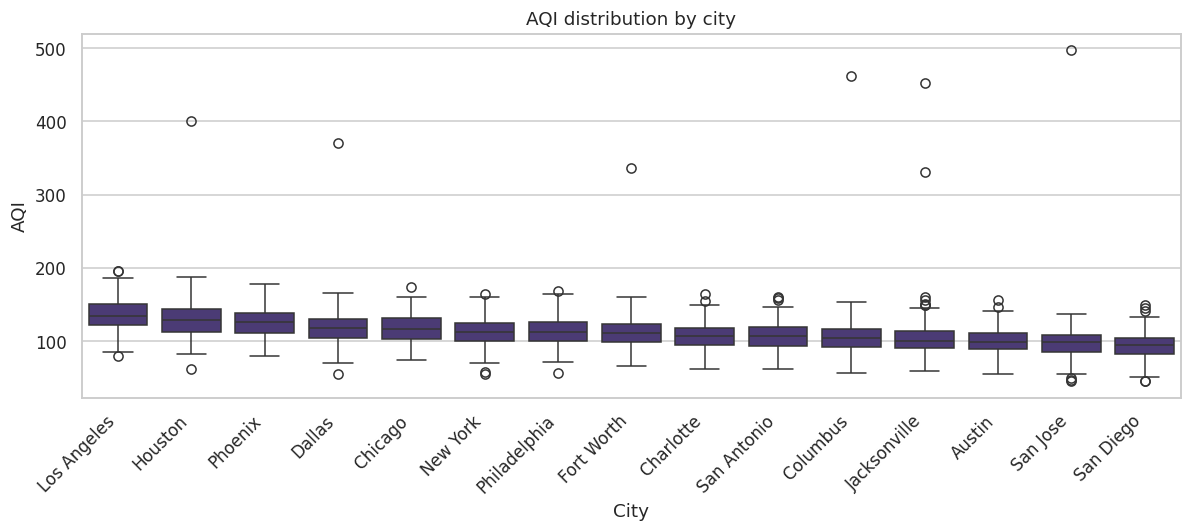

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
city_order = df.groupby("City")["AQI"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="City", y="AQI", order=city_order, ax=ax)
plt.xticks(rotation=45, ha="right")
ax.set_title("AQI distribution by city")
plt.tight_layout()
plt.show()

Median AQI varies noticeably by city, with some cities consistently trending worse than
others — this is useful signal that justifies keeping `City` as a model feature rather
than dropping it.

### 5.6 AQI trend over time

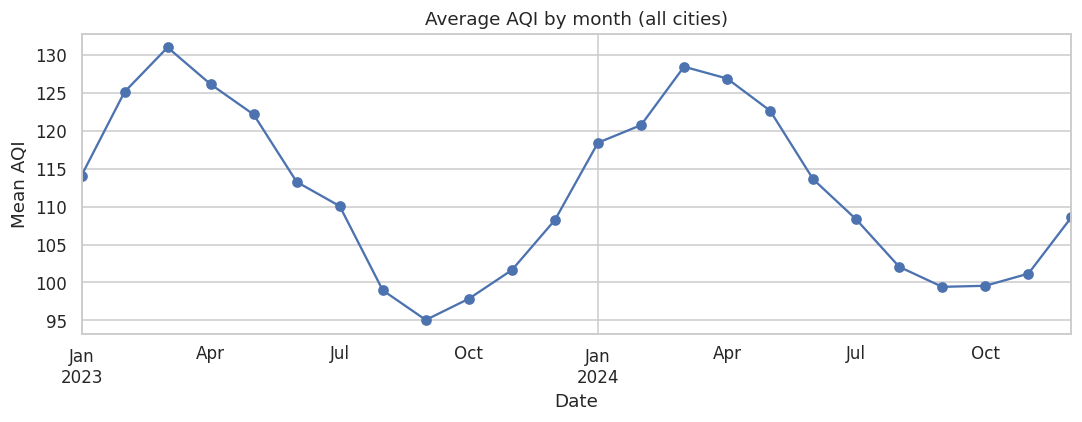

In [8]:
monthly = df.set_index("Date").resample("ME")["AQI"].mean()

fig, ax = plt.subplots(figsize=(10, 4))
monthly.plot(ax=ax, marker="o", color="#4C72B0")
ax.set_title("Average AQI by month (all cities)")
ax.set_ylabel("Mean AQI")
plt.tight_layout()
plt.show()

There's a visible seasonal pattern — AQI tends to rise in warmer months, which lines up
with the positive Temperature correlation seen above and with ozone formation being a
summer phenomenon. This motivates engineering a `Month`/`Season` feature in preprocessing.

### 5.7 Pollutant vs AQI relationships

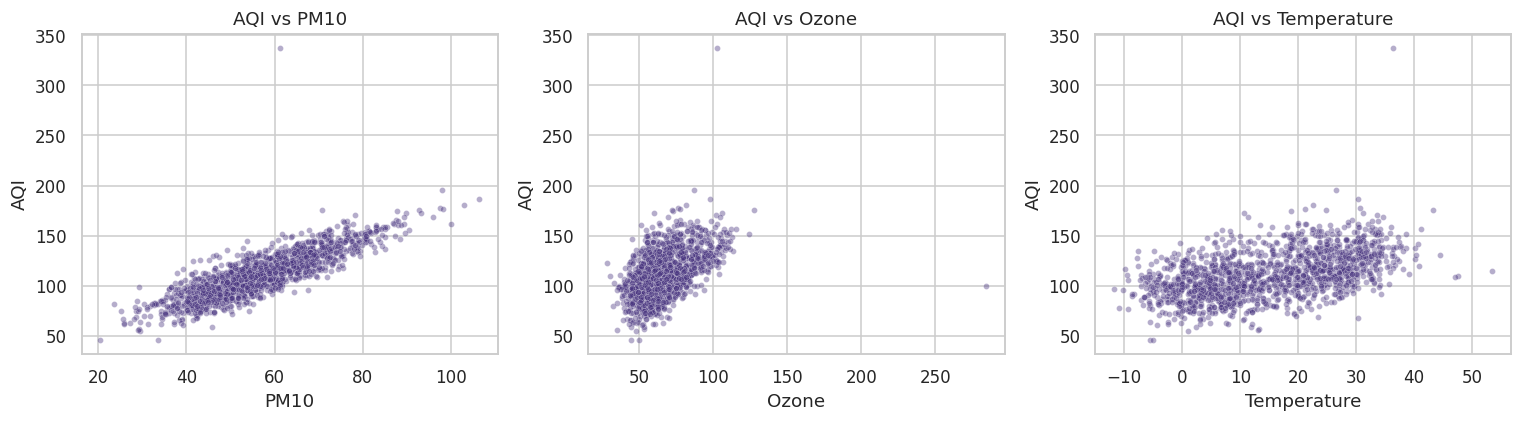

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["PM10", "Ozone", "Temperature"]):
    sns.scatterplot(data=df.sample(1500, random_state=42), x=col, y="AQI", ax=ax, alpha=0.4, s=15)
    ax.set_title(f"AQI vs {col}")
plt.tight_layout()
plt.show()

## 6. Preprocessing Pipeline

Based on the EDA above, the pipeline needs to:
1. Remove exact duplicate rows.
2. Drop rows with a missing **target** (`AQI`) — we can't train or evaluate on a row
   with no label, and only ~2% of rows are affected.
3. Engineer `Month` and `Season` from `Date` to capture the seasonal pattern found in 5.6.
4. Impute missing **predictor** values (median for numeric columns — robust to the
   skew we saw in AQI and, by extension, likely present in some pollutants).
5. Scale numeric features (StandardScaler) — required for distance-based models like
   KNN, and harmless for tree/ensemble models.
6. One-hot encode the categorical `City` feature.
7. Build the classification target `AQI_Category` (already engineered in 5.3) alongside
   the regression target `AQI`.
8. Split into train/test sets — with `stratify=` on the classification target to preserve
   the (imbalanced) class proportions in both splits.

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- Step 1-2: de-duplicate and drop missing-target rows ---
clean = df.drop_duplicates().dropna(subset=["AQI"]).reset_index(drop=True)
print(f"After removing duplicates & missing targets: {clean.shape[0]} rows (from {df.shape[0]})")

# --- Step 3: date-based feature engineering ---
def season_from_month(m):
    if m in (12, 1, 2):
        return "Winter"
    elif m in (3, 4, 5):
        return "Spring"
    elif m in (6, 7, 8):
        return "Summer"
    else:
        return "Fall"

clean["Month"] = clean["Date"].dt.month
clean["Season"] = clean["Month"].apply(season_from_month)
clean["DayOfWeek"] = clean["Date"].dt.dayofweek

# --- Define feature groups ---
numeric_features = ["PM2.5", "PM10", "Ozone", "NO2", "CO", "SO2", "Temperature", "Humidity"]
categorical_features = ["City", "Season"]

X = clean[numeric_features + categorical_features + ["Month", "DayOfWeek"]]
y_reg = clean["AQI"]
y_clf = clean["AQI_Category"].astype(str)

# --- Steps 4-6: impute + scale numeric, impute + one-hot categorical ---
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features + ["Month", "DayOfWeek"]),
    ("cat", categorical_pipeline, categorical_features),
])

# --- Step 8: train/test split (stratified on the classification target) ---
X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print(f"Train shape after preprocessing: {X_train_processed.shape}")
print(f"Test shape after preprocessing:  {X_test_processed.shape}")
print(f"\nClass balance preserved in train split:\n{y_clf_train.value_counts(normalize=True).round(3)}")

After removing duplicates & missing targets: 5387 rows (from 5583)
Train shape after preprocessing: (4309, 29)
Test shape after preprocessing:  (1078, 29)

Class balance preserved in train split:
AQI_Category
Unhealthy (Sensitive)    0.632
Moderate                 0.320
Unhealthy                0.045
Hazardous                0.001
Good                     0.001
Name: proportion, dtype: float64


The pipeline is expressed as a single `ColumnTransformer` wrapped in `sklearn.pipeline.Pipeline`
objects, so it can be fit once on the training split and reused identically (via `.transform()`)
on the test split and on any new incoming data in Phase 2 — with no risk of data leakage from
test into train, since `fit_transform` is only ever called on `X_train`.

## 7. Model Shortlist

Two complementary sub-problems come out of this dataset, so the shortlist below covers
both — three regression models for the continuous `AQI` target, and three classification
models for the `AQI_Category` target. Two are ensembles, satisfying the ensembling
requirement.

| # | Model | Task | Why it's on the list |
|---|---|---|---|
| 1 | **Multiple Linear Regression** | Regression | Interpretable baseline; coefficients directly show each pollutant's contribution to AQI. |
| 2 | **KNN Regressor** | Regression | Captures non-linear relationships between pollutants and AQI that a linear model can't. |
| 3 | **Random Forest Regressor** *(ensemble)* | Regression | Averages many decision trees to reduce variance and typically outperforms both models above on skewed, real-world targets like AQI. |
| 4 | **Logistic Regression** | Classification | Standard, interpretable baseline for the multi-class AQI category problem. |
| 5 | **Decision Tree Classifier** | Classification | Non-linear, human-readable decision boundaries; a natural point of comparison for model #6. |
| 6 | **Random Forest Classifier** *(ensemble)* | Classification | An ensemble of model #5; expected to handle the class imbalance and non-linear boundaries better than a single tree. |

**Evaluation plan for Phase 2:** regression models will be compared with RMSE and R²;
classification models will be compared with macro-F1 (not raw accuracy, given the class
imbalance found in Section 5.3) and a confusion matrix.

## 8. Summary

- **Dataset:** 5,583 daily records across 15 US cities (2023–2024), with AQI, six
  pollutant concentrations, and two weather variables.
- **Key EDA findings:** AQI is right-skewed with a long hazardous-air tail; PM10 and
  Ozone are the strongest predictors; AQI varies by both city and season; the natural
  AQI-category classes are highly imbalanced.
- **Preprocessing:** de-duplication, median imputation, date-based feature engineering
  (Month/Season/DayOfWeek), scaling, and one-hot encoding — all wrapped in a single
  leak-safe `ColumnTransformer` pipeline.